## IMDB Sentiment Analysis using Embeddings

In [1]:
from keras.datasets import imdb
from keras import Sequential
from keras.layers import Dense, SimpleRNN, Flatten, Input, Embedding
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

In [2]:
(X_train, y_train), (X_test, y_test) = imdb.load_data()

In [3]:
X_train = pad_sequences(X_train, padding='post', maxlen=50)
X_test = pad_sequences(X_test, padding='post', maxlen=50)

In [8]:
print("Maximum token ID:", X_train.max())
print("Maximum token ID in test:", X_test.max())

Maximum token ID: 88585
Maximum token ID in test: 88582


In [9]:
model = Sequential([
    Input(shape=(50,)),
    Embedding(input_dim=88586, output_dim=2),
    SimpleRNN(32, return_sequences=False),
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 2)          │       177,172 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         1,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,325 (696.58 KB)

 Trainable params: 178,325 (696.58 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [11]:
history = model.fit(X_train, y_train, epochs=5, validation_data=(X_test, y_test))

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.5991 - loss: 0.6362 - val_accuracy: 0.7842 - val_loss: 0.4580
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.8312 - loss: 0.3857 - val_accuracy: 0.8152 - val_loss: 0.4143
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9042 - loss: 0.2488 - val_accuracy: 0.8000 - val_loss: 0.4625
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - accuracy: 0.9413 - loss: 0.1666 - val_accuracy: 0.7918 - val_loss: 0.5741
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.9620 - loss: 0.1144 - val_accuracy: 0.7836 - val_loss: 0.5848


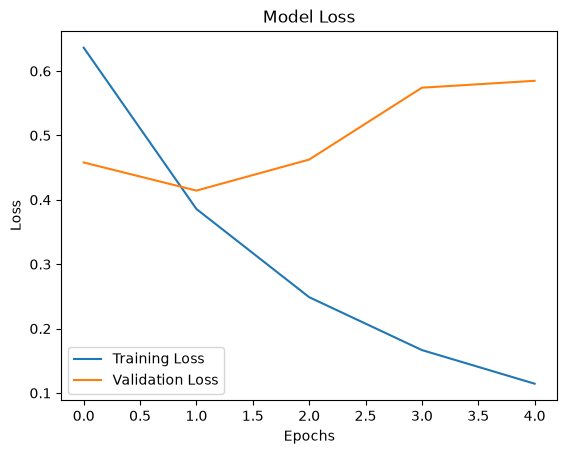

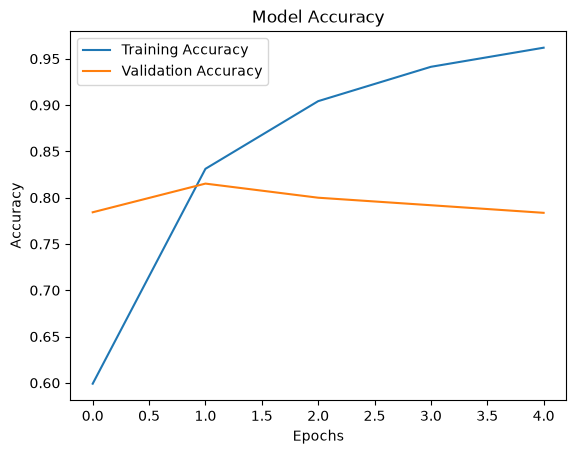

In [12]:
import matplotlib.pyplot as plt

# Plot Loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Plot Accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()